# Coding a Quantum Chemistry Algorithm (VQE) with Qiskit
---
### Two parts: 

<table style="width: 100%; border-collapse: collapse; border: none;">
  <tr>
    <td style="width: 50%; vertical-align: middle; text-align: center; padding: 16px; font-size: 22px; border: none;">
      <strong>Part 1. Qiskit basics</strong><br>
      <img src="images/basic_circuit.png" alt="basic_circuit" style="width: 420px; object-fit: contain; display: block; margin: 16px auto 0 auto;" />
    </td>
    <td style="width: 50%; vertical-align: middle; text-align: center; padding: 16px; font-size: 22px; border: none;">
      <strong>Part 2. Solving the ground state of H2</strong><br>
      <img src="images/h2_landscape.png" alt="h2_landscape" style="width: 350px; height: 280px; object-fit: contain; display: block; margin: 16px auto 0 auto;" />
    </td>
  </tr>
</table>

In [1]:
import qiskit
print(qiskit.__version__)

2.4.1


# Part 1 - Qiskit Basics

## 1.1. Build a Quantum Circuit

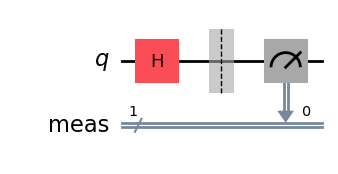

In [2]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)
qc.h(qubit=0)

qc.measure_all()

qc.draw(output='mpl')

## 1.2. Visualise effect on Bloch Sphere

In [3]:
from qiskit.visualization.bloch import Bloch

def statevector_to_bloch(statevec):
    """ 
    Helper function to convert 1-qubit statevector 
    (|ψ⟩ = α|0⟩ + β|1) = quantum state of the probabilities of |0> and |1>) 
    to 3-dimensional Bloch coordinates x, y, z.
    """
    
    alpha = statevec[0] # Probability amplitude for |0> (North Pole)
    beta = statevec[1] # Probability amplitude for |1> (South Pole)
    x = 2 * (alpha.conjugate() * beta).real
    y = 2 * (alpha.conjugate() * beta).imag
    z = abs(alpha)**2 - abs(beta)**2
    return [x, y, z]

def plot_bloch_states(vectors, labels=None, colors=None):
    """ 
    Visualizes quantum states of qubits, stored in vectors, 
    on the Bloch sphere with optional labels and colors.
    """
    b = Bloch()

    for v in vectors:
        b.add_vectors(v)

    if colors:
        b.vector_color = colors

    if labels:
        for v, label in zip(vectors, labels):
            b.add_annotation(v, label)

    b.show()

Initial statevector: [1.+0.j 0.+0.j]
Final statevector: [0.70710678+0.j 0.70710678+0.j]


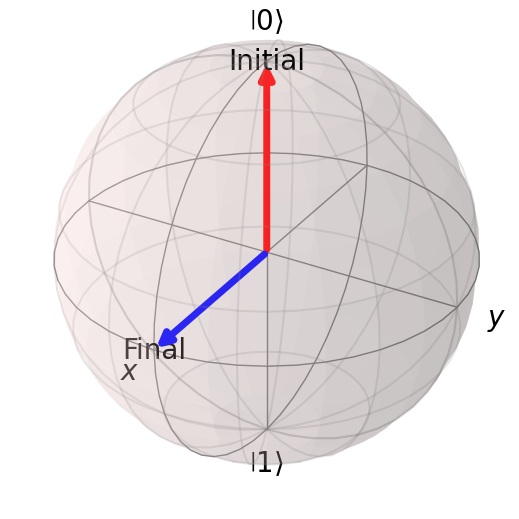

In [4]:
from qiskit.quantum_info import Statevector

circuit = QuantumCircuit(1)
circuit.h(qubit=0)

initial_state = Statevector.from_label('0')
final_state = initial_state.evolve(circuit)

print("Initial statevector:", initial_state.data)
print("Final statevector:", final_state.data)

plot_bloch_states(
    [
        statevector_to_bloch(initial_state.data),
        statevector_to_bloch(final_state.data)
    ],
    labels=["Initial", "Final"],
    colors=["r", "b"]
)

## 1.3. Multiple qubits

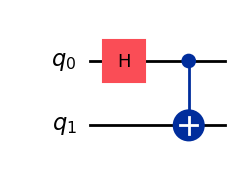

In [5]:
bell_circuit = QuantumCircuit(2)
bell_circuit.h(0)
bell_circuit.cx(0, 1)

bell_circuit.draw(output='mpl')

In [6]:
initial_state = Statevector.from_label("00")
final_state = initial_state.evolve(bell_circuit)

print("Statevector:")
print(final_state.data)

print("\nMeasurement probabilities:")
print(final_state.probabilities_dict())

Statevector:
[0.70710678+0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]

Measurement probabilities:
{np.str_('00'): np.float64(0.4999999999999999), np.str_('11'): np.float64(0.4999999999999999)}


$$\renewcommand{\ket}[1]{|#1\rangle}$$

The circuit we made turned the $\ket{00} = (1,0,0,0)$ state into the entangled Bell state $\ket{\Phi^+} = \dfrac{1}{\sqrt{2}} (\ket{00} + \ket{11}) = \dfrac{1}{\sqrt{2}}(1,0,0,1)$.

{'11': 5164, '00': 4836}


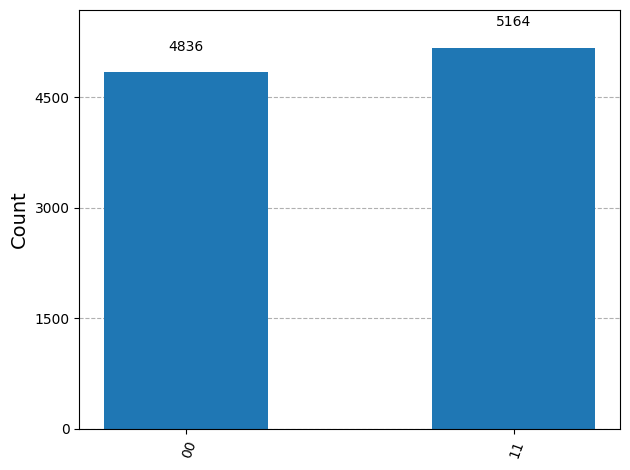

In [7]:
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Measure qubit 0/(1) into cbit 0/(1)
measured_circuit = bell_circuit.measure_all(inplace=False)

# Instantiate hardware
simulator = AerSimulator()

# Run the circuit on the (virtual) hardware
result = simulator.run(measured_circuit, shots=10000).result()
counts = result.get_counts()

print(counts)
plot_histogram(counts)

## 1.4. Parameterized (Variational) circuits

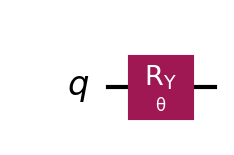

In [8]:
from qiskit.circuit import Parameter

theta = Parameter("θ")
parameterized_circuit = QuantumCircuit(1)
parameterized_circuit.ry(theta, 0)
parameterized_circuit.draw(output='mpl', scale=1.5)

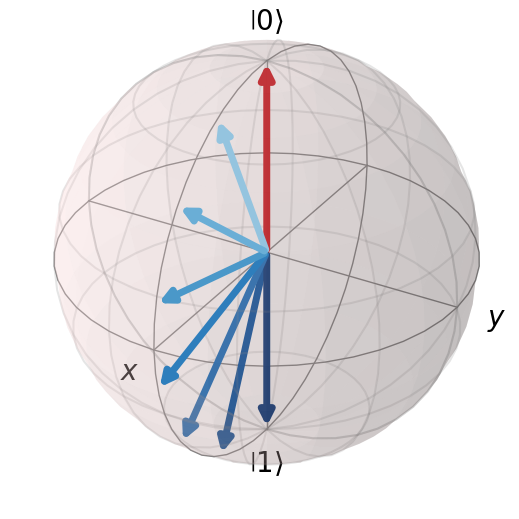

In [9]:
import numpy as np
import matplotlib.cm as cm

angle_list = np.linspace(0, np.pi, 8)
circuit_list = [parameterized_circuit.assign_parameters({theta: angle}) for angle in angle_list]

vectors = []
for circuit in circuit_list:
    initial_vector = Statevector.from_label('0')
    evolved_vector = initial_vector.evolve(circuit)
    coords = statevector_to_bloch(evolved_vector)
    vectors.append(coords)

colors = [cm.Blues(i) for i in np.linspace(0.4, 1.0, len(vectors)-1)]
colors.insert(0, cm.Reds(0.8))

plot_bloch_states(vectors, colors=colors)

# Part 2 - Solving the Ground State of H2

## Variational Quantum Eigensolver (VQE)

[reference: https://quantum.cloud.ibm.com/learning/en/courses/quantum-diagonalization-algorithms/vqe]

The Variational Quantum Eigensolver (VQE) is a hybrid algorithm designed to find the ground state of a system. In physics and chemistry, everything wants to be in its lowest energy state. If we can find that state, we can understand how molecules bond, how materials conduct electricity, or even how to optimize complex logistics routes.

Given a system described by a mathematical operator called a Hamiltonian ($H$), VQE finds the lowest possible eigenvalue (the ground state energy) and its corresponding eigenvector (the wavefunction). An important ingredient in VQE is the variational principle, which states that no trial wavefunction can have an energy that is lower than the ground state wavefunction. 

Because finding the ground state is computationally expensive for classical computers as systems get larger, we use a quantum circuit to prepare candidate states and a classical optimizer to nudge the parameters until we find the minimum.

<div align="center">
  <img src="images/variational_algorithms.png" style="transform: scaleX(1.0);" alt="Hydrogen Bond" />
</div>

---

## 2.1 $H_2$ Hamiltonian

In [10]:
from qiskit_nature.second_q.drivers import PySCFDriver

driver = PySCFDriver(
    atom="H 0 0 0; H 0 0 0.735",
    basis="sto3g",  # minimal basis
)
problem = driver.run()
fermionic_op = problem.hamiltonian.second_q_op()
print(fermionic_op)

Fermionic Operator
number spin orbitals=4, number terms=36
  -1.2563390730032502 * ( +_0 -_0 )
+ -0.4718960072811419 * ( +_1 -_1 )
+ -1.2563390730032502 * ( +_2 -_2 )
+ -0.4718960072811419 * ( +_3 -_3 )
+ 0.33785507740175835 * ( +_0 +_0 -_0 -_0 )
+ 0.33229086512764827 * ( +_0 +_1 -_1 -_0 )
+ 0.33785507740175835 * ( +_0 +_2 -_2 -_0 )
+ 0.33229086512764827 * ( +_0 +_3 -_3 -_0 )
+ 0.09046559989211568 * ( +_0 +_0 -_1 -_1 )
+ 0.09046559989211568 * ( +_0 +_1 -_0 -_1 )
+ 0.09046559989211568 * ( +_0 +_2 -_3 -_1 )
+ 0.09046559989211568 * ( +_0 +_3 -_2 -_1 )
+ 0.09046559989211568 * ( +_1 +_0 -_1 -_0 )
+ 0.09046559989211568 * ( +_1 +_1 -_0 -_0 )
+ 0.09046559989211568 * ( +_1 +_2 -_3 -_0 )
+ 0.09046559989211568 * ( +_1 +_3 -_2 -_0 )
+ 0.33229086512764827 * ( +_1 +_0 -_0 -_1 )
+ 0.349286861366008 * ( +_1 +_1 -_1 -_1 )
+ 0.33229086512764827 * ( +_1 +_2 -_2 -_1 )
+ 0.349286861366008 * ( +_1 +_3 -_3 -_1 )
+ 0.33785507740175835 * ( +_2 +_0 -_0 -_2 )
+ 0.33229086512764827 * ( +_2 +_1 -_1 -_2 )
+ 0.33785

The printout describes the $H_2$ Hamiltonian in second quantization, capturing every physical interaction (electrons moving, nuclei pulling them, and electrons repelling each other). It is written in terms of fermionic operators, which cannot be directly executed on qubits. 

To make the Hamiltonian compatible with a quantum circuit, we apply the Jordan–Wigner transformation. This maps the occupation of spin-orbitals to qubits:

In [11]:
from qiskit_nature.second_q.mappers import JordanWignerMapper

mapper = JordanWignerMapper()
qubit_op = mapper.map(fermionic_op)

for pauli, coeff in qubit_op.to_list():
    print(f"{pauli}  {coeff.real}")

IIII  -0.8105479805373283
IIIZ  0.17218393261915557
IIZI  -0.22575349222402352
IZII  0.17218393261915557
ZIII  -0.2257534922240235
IIZZ  0.1209126326177663
IZIZ  0.16892753870087918
ZIIZ  0.16614543256382414
YYYY  0.04523279994605784
XXYY  0.04523279994605784
YYXX  0.04523279994605784
XXXX  0.04523279994605784
IZZI  0.16614543256382414
ZIZI  0.174643430683004
ZZII  0.1209126326177663



#### Physical Categories of the Terms
The 15 resulting lines fall into four main physical groups:

* **Constant Offset** (`IIII`): 
  * Represents the fixed electrostatic repulsion between the two positively charged nuclei (protons pushing apart).
* **Single-Z Terms** (`IIIZ`, `IIZI`, etc.): 
  * Measure **local orbital energies** and baseline chemical potential (whether orbitals are occupied or empty).
* **Two-Z Terms** (`IIZZ`, `ZIZI`, etc.): 
  * Represent **Coulomb repulsions** between electrons in different orbitals.
* **Multi-X and Multi-Y Terms** (`XXXX`, `YYYY`, etc.): 
  * Capture **quantum fluctuations and electron correlation**—allowing electrons to move between orbitals, which is essential for accurate energy calculation beyond Hartree-Fock.

#### How VQE Uses This
During VQE, the quantum computer measures the expectation value of every single Pauli string line for a given trial state, multiplies it by its coefficient, and sums them up to calculate the total molecular energy.

---

## 2.2 Exact solution

In [12]:
from qiskit.quantum_info import SparsePauliOp
import numpy as np

h2_hamiltonian = SparsePauliOp.from_list(qubit_op.to_list())
 
nuclear_repulsion = 0.71997
A = np.array(h2_hamiltonian)
eigenvalues, eigenvectors = np.linalg.eig(A)
print("Electronic ground state energy (Hartree): ", min(eigenvalues).real)
print("Nuclear repulsion energy (Hartree): ", nuclear_repulsion)
print(
    "Total ground state energy (Hartree): ", min(eigenvalues).real + nuclear_repulsion
)
h2 = min(eigenvalues).real + nuclear_repulsion

Electronic ground state energy (Hartree):  -1.8572750302023802
Nuclear repulsion energy (Hartree):  0.71997
Total ground state energy (Hartree):  -1.1373050302023802


## 2.3: Build an ansatz

Now that we have a Hamiltonian, we want to find its ground state. To do this, we prepare trial quantum states using `QuantumCircuit`s and compute their expectation value with the Hamiltonian (which gives the energy of that state). We create parameterized `QuantumCircuit`s to build these trial states, then vary the parameters until we converge on a minimum energy.

These trial states are called an ansatz (a German word meaning “approach” or “method”). The better our ansatz can represent the true ground state, the closer our minimum energy will be to the actual ground state energy.

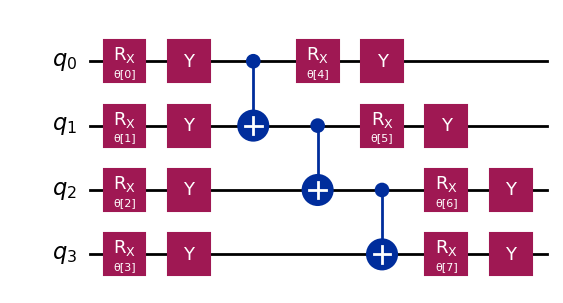

In [13]:
from qiskit.circuit.library import efficient_su2
 
SU2_ansatz = efficient_su2(4, su2_gates=["rx", "y"], entanglement="linear", reps=1)
SU2_ansatz.draw(output="mpl")

## 2.4 Define a cost function

This function computes the energy of the current trial state during the VQE optimization.

It takes the current circuit parameters, prepares the corresponding quantum state using the ansatz, and uses the Estimator to calculate the expectation value of the Hamiltonian — which is the energy of that state.

In [14]:
def cost_func(params, ansatz, hamiltonian, estimator, cost_history_dict):
    """
    Return estimate of energy from estimator
 
    Parameters:
        params (ndarray): Array of ansatz parameters
        ansatz (QuantumCircuit): Parameterized ansatz circuit
        hamiltonian (SparsePauliOp): Operator representation of Hamiltonian
        estimator (EstimatorV2): Estimator primitive instance
        cost_history_dict: Dictionary for storing intermediate results
 
    Returns:
        float: Energy estimate
    """
    pub = (ansatz, [hamiltonian], [params])
    result = estimator.run(pubs=[pub]).result()
    energy = result[0].data.evs[0] 
 
    cost_history_dict["iters"] += 1
    cost_history_dict["prev_vector"] = params 
    cost_history_dict["cost_history"].append(energy)
    print(f"Iters. done: {cost_history_dict['iters']} [Current cost: {energy}]")
 
    return energy

## 2.5 Minimize

In [15]:
from scipy.optimize import minimize
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit_ibm_runtime import EstimatorOptions

simulator = AerSimulator()
options = EstimatorOptions()
options.default_shots = 100000
options.resilience_level = 1
options.dynamical_decoupling.enable = True
estimator = Estimator(simulator, options=options)

# Initial guess (set all parameter values to 0)
x0 = [0]*len(SU2_ansatz.parameters)

cost_history_dict = {
    "prev_vector": None,
    "iters": 0,
    "cost_history": [],
}
result = minimize(
    cost_func,
    x0,
    args=(SU2_ansatz, h2_hamiltonian, estimator, cost_history_dict),
    method="cobyla",
    options={"maxiter": 100, "tol": 1e-12},
)

/Users/joeyrogers/Qiskit-fundamentals/.venv/lib/python3.14/site-packages/qiskit_ibm_runtime/fake_provider/local_service.py:187: UserWarning: The resilience_level option has no effect in local testing mode.
  warnings.warn("The resilience_level option has no effect in local testing mode.")
/Users/joeyrogers/Qiskit-fundamentals/.venv/lib/python3.14/site-packages/qiskit_ibm_runtime/fake_provider/local_service.py:271: UserWarning: Options {'dynamical_decoupling': {'enable': True}} have no effect in local testing mode.
  warnings.warn(f"Options {options_copy} have no effect in local testing mode.")


Iters. done: 1 [Current cost: -0.24479582170347317]
Iters. done: 2 [Current cost: -0.6145354219434715]
Iters. done: 3 [Current cost: -0.7119591059794407]
Iters. done: 4 [Current cost: -0.7653449725347319]
Iters. done: 5 [Current cost: -0.7514295035670687]
Iters. done: 6 [Current cost: -0.7177362639704197]
Iters. done: 7 [Current cost: -0.7743610170142691]
Iters. done: 8 [Current cost: -0.7318123395625722]
Iters. done: 9 [Current cost: -0.733018414215982]
Iters. done: 10 [Current cost: -1.0476990338052101]
Iters. done: 11 [Current cost: -1.0852151056615824]
Iters. done: 12 [Current cost: -0.9969941460892389]
Iters. done: 13 [Current cost: -1.1140651457623987]
Iters. done: 14 [Current cost: -1.2673058336770655]
Iters. done: 15 [Current cost: -1.1667633019372716]
Iters. done: 16 [Current cost: -1.2084839393995022]
Iters. done: 17 [Current cost: -1.049304480578166]
Iters. done: 18 [Current cost: -1.2687863096846033]
Iters. done: 19 [Current cost: -1.2420017937115724]
Iters. done: 20 [Curre

## 2.6 Verify result

In [16]:
h_vqe = result.fun
parameters = result.x
print("The reference ground state energy is ", min(eigenvalues).real)
print("The computed ground state energy is ", h_vqe)
print("Parameter vector is", parameters)

The reference ground state energy is  -1.8572750302023802
The computed ground state energy is  -1.8366364118864695
Parameter vector is [ 3.15186405 -0.01932834  0.03103247 -0.75273216 -0.03027727 -0.02954372
 -0.05631763 -0.7698182 ]


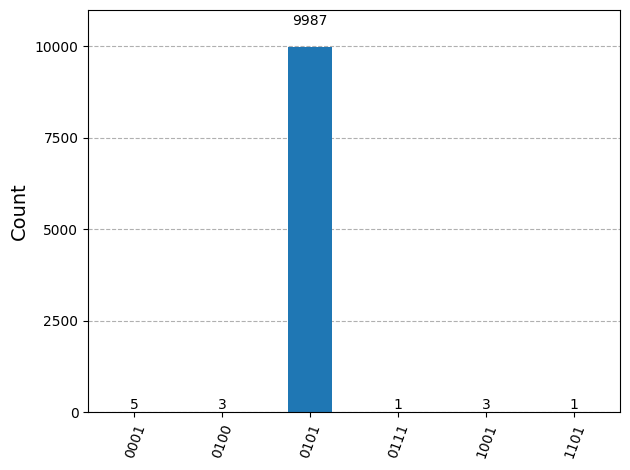

In [17]:
bound_circuit = SU2_ansatz.assign_parameters(parameters)
bound_circuit.draw(output='mpl')

measured_circuit = bound_circuit.measure_all(inplace=False)
simulator = AerSimulator()
result = simulator.run(measured_circuit, shots=10000).result()

counts = result.get_counts()
plot_histogram(counts)

### Ground State Representation of H₂ (|0101⟩)

When running VQE for the H₂ molecule using standard Qiskit Nature settings, the dominant state measured at the end is `|0101` (comprising ~99% of the state vector amplitude). 

#### 1. Spin-Orbital Mapping & Block Ordering
Qiskit Nature defaults to **block ordering** for mapping molecular spin-orbitals to qubits. Instead of alternating spin-up and spin-down, it groups all spin-up ($\uparrow$) orbitals first, followed by all spin-down ($\downarrow$) orbitals:

* **q₀**: Bonding spin-up ($\sigma\uparrow$)
* **q₁**: Anti-bonding spin-up ($\sigma^*\uparrow$)
* **q₂**: Bonding spin-down ($\sigma\downarrow$)
* **q₃**: Anti-bonding spin-down ($\sigma^*\downarrow$)

#### 2. Bit Ordering in Qiskit
Qiskit uses **little-endian** notation, meaning qubit string indices read from right to left: 

$$\text{|q}_3\text{ q}_2\text{ q}_1\text{ q}_0\rangle$$

#### 3. Why `|0101⟩` Makes Physical Sense
In the Hartree-Fock ground state of H₂, both electrons occupy the lower-energy bonding spatial orbital ($\sigma_g$): one with spin-up and one with spin-down.

* **q₀** ($\sigma\uparrow$) is **occupied** $\rightarrow$ `1`
* **q₁** ($\sigma^*\uparrow$) is unoccupied $\rightarrow$ `0`
* **q₂** ($\sigma\downarrow$) is **occupied** $\rightarrow$ `1`
* **q₃** ($\sigma^*\downarrow$) is unoccupied $\rightarrow$ `0`

Assembling these into little-endian string order `|q₃ q₂ q₁ q₀⟩` gives:

$$|0\,1\,0\,1\rangle$$

<div align="center">
  <img src="images/hydrogenbond.jpg" style="transform: scaleX(1.0);" alt="Hydrogen Bond" />
</div>

[LibreTexts: Chemistry - Molecular Orbital Theory](https://chem.libretexts.org/Under_Construction/Purgatory/AUCHE_230_-_Structure_and_Bonding/03%3A_Molecular_Orbital_Theory/3.01%3A_Molecular_Orbital_Theory)

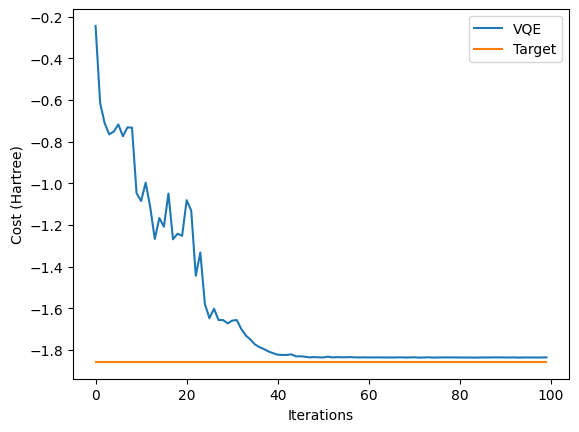

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
x = np.linspace(0, 10, 100)
 
# Define the constant function
y_constant = np.full_like(x, min(eigenvalues.real))
ax.plot(
    range(cost_history_dict["iters"]), cost_history_dict["cost_history"], label="VQE"
)
ax.set_xlabel("Iterations")
ax.set_ylabel("Cost (Hartree)")
ax.plot(y_constant, label="Target")
plt.legend()
plt.draw()

In [19]:
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA

vqe_solver = VQE(
    ansatz=SU2_ansatz,
    optimizer=COBYLA(maxiter=100),
    estimator=estimator,
    initial_point=[0.5] * SU2_ansatz.num_parameters,
)

result = vqe_solver.compute_minimum_eigenvalue(h2_hamiltonian)
print(f"Built-in VQE energy: {result.eigenvalue.real:.6f} Hartree")
print(f"Our VQE energy:      {h_vqe:.6f} Hartree")
print(f"Exact energy:        {min(eigenvalues).real:.6f} Hartree")

/Users/joeyrogers/Qiskit-fundamentals/.venv/lib/python3.14/site-packages/qiskit_ibm_runtime/fake_provider/local_service.py:187: UserWarning: The resilience_level option has no effect in local testing mode.
  warnings.warn("The resilience_level option has no effect in local testing mode.")
/Users/joeyrogers/Qiskit-fundamentals/.venv/lib/python3.14/site-packages/qiskit_ibm_runtime/fake_provider/local_service.py:271: UserWarning: Options {'dynamical_decoupling': {'enable': True}} have no effect in local testing mode.
  warnings.warn(f"Options {options_copy} have no effect in local testing mode.")


Built-in VQE energy: -1.836266 Hartree
Our VQE energy:      -1.836636 Hartree
Exact energy:        -1.857275 Hartree
